In [ ]:
from google.colab import files
import os, glob, shutil, requests, time, subprocess

os.chdir('/content')

# ---------------- SETTINGS ----------------
SEEDS = [42]                    # [42, 43, 44] -> mean +/- std (3x longer)
NUM_EPOCHS = None               # None = 30 epochs from the YAML (REAL RUN). Use 2 only for a quick debug.
DATASETS_TO_RUN = ["C16", "C17", "BRACS"]
RUN_ABLATION = True             # mean-pooling ablation (trains each dataset once more)
ZENODO_RECORD = "23130543"
HF_REPO = "LeonYe/ECE1512-WSI-Feature"
MANUAL_H5 = {"C16": None, "C17": None, "BRACS": None}   # optional: paths of .h5 files already in /content
# ------------------------------------------

# ---- 1) upload the zip ----
print(">>> Click 'Choose files' and select Project_A_Starter_Code.zip")
uploaded = files.upload()
zip_names = [n for n in uploaded if n.lower().endswith('.zip')]
assert zip_names, "No .zip uploaded. Run this cell again and choose the zip."
ZIP_PATH = os.path.join('/content', zip_names[0])
del uploaded
print("ZIP_PATH =", ZIP_PATH)

# ---- helpers ----
def tag_of(name):
    n = name.upper()
    if "BRACS" in n: return "BRACS"
    if "C17" in n or "CAMELYON17" in n: return "C17"
    if "C16" in n or "CAMELYON16" in n: return "C16"
    return None

def download(url, out):
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0)); done = 0; t0 = time.time()
        with open(out, "wb") as f:
            for chunk in r.iter_content(chunk_size=1 << 24):
                f.write(chunk); done += len(chunk)
                print(f"\r  {done/1e9:.2f}/{total/1e9:.2f} GB  ({done/1e6/max(time.time()-t0,1e-9):.0f} MB/s)", end="")
    print()

# ---- 2) datasets: Zenodo -> Hugging Face -> manual upload ----
H5_PATHS = {k: v for k, v in MANUAL_H5.items() if v}
os.makedirs('/content/datasets', exist_ok=True)

zen_files = []
try:
    rec = requests.get(f"https://zenodo.org/api/records/{ZENODO_RECORD}", timeout=30).json()
    zen_files = rec.get("files", [])
    print("\nFiles in the Zenodo record:")
    for f in zen_files:
        print(f"  {f.get('key', f.get('filename', '?')):70s} {f.get('size', 0)/1e9:6.2f} GB")
except Exception as e:
    print("Zenodo listing failed:", e)

for key in DATASETS_TO_RUN:
    if key in H5_PATHS:
        continue
    out = f"/content/datasets/{key}.h5"
    for f in zen_files:
        name = f.get('key', f.get('filename', ''))
        if name.lower().endswith(".h5") and tag_of(name) == key:
            url = f.get("links", {}).get("self") or f"https://zenodo.org/records/{ZENODO_RECORD}/files/{name}?download=1"
            print(f"[{key}] downloading {name} from Zenodo")
            try:
                download(url, out); H5_PATHS[key] = out
            except Exception as e:
                print("  failed:", e)
            break

missing = [k for k in DATASETS_TO_RUN if k not in H5_PATHS]
if missing:
    try:
        subprocess.run(["pip", "install", "-q", "huggingface_hub"], check=True)
        from huggingface_hub import list_repo_files, hf_hub_download
        hf_files = list_repo_files(HF_REPO, repo_type="dataset")
        print("\nFiles in the Hugging Face repo:", *hf_files, sep="\n  ")
        for key in missing:
            for f in hf_files:
                if f.lower().endswith(".h5") and tag_of(f) == key:
                    print(f"[{key}] downloading {f} from Hugging Face")
                    p = hf_hub_download(HF_REPO, f, repo_type="dataset", local_dir="/content/datasets/hf")
                    H5_PATHS[key] = p
                    break
    except Exception as e:
        print("Hugging Face step failed:", e)

for key in [k for k in DATASETS_TO_RUN if k not in H5_PATHS]:
    print(f"\n>>> [{key}] could not be downloaded automatically. Upload the {key} .h5 file now:")
    up = files.upload()
    names = [n for n in up if n.lower().endswith('.h5')]
    assert names, f"No .h5 uploaded for {key}."
    dst = f"/content/datasets/{key}.h5"
    shutil.move(os.path.join('/content', names[0]), dst)
    H5_PATHS[key] = dst
    del up

print("\n===== SUMMARY =====")
print("ZIP :", ZIP_PATH)
for k in DATASETS_TO_RUN:
    print(f"{k:6s}:", H5_PATHS[k], f"({os.path.getsize(H5_PATHS[k])/1e9:.2f} GB)")

>>> Click 'Choose files' and select Project_A_Starter_Code.zip


Saving Project_A_Starter_Code.zip to Project_A_Starter_Code.zip
ZIP_PATH = /content/Project_A_Starter_Code.zip

Files in the Zenodo record:
  C17.zip                                                                  3.74 GB
  BRACS.zip                                                                3.89 GB
  C16.zip                                                                  6.68 GB



Files in the Hugging Face repo:
  .gitattributes
  feature/BRACS.zip
  feature/BRACS/patch_feats_pretrain_medical_ssl.h5
  feature/C16.zip
  feature/C16/patch_feats_pretrain_medical_ssl.h5
  feature/C17.zip
  feature/C17/patch_feats_pretrain_medical_ssl.h5
  slide/test_067.tif
  slide/test_068.tif
  slide/test_068.xml
[C16] downloading feature/C16/patch_feats_pretrain_medical_ssl.h5 from Hugging Face


feature/C16/patch_feats_pretrain_medical(…): reconstructing file:   0%|          |  0.00B / 7.22GB            

feature/C16/patch_feats_pretrain_medical(…): downloading bytes:           |  0.00B            

...

feature/C17/patch_feats_pretrain_medical(…): downloading bytes:           |  0.00B            

[BRACS] downloading feature/BRACS/patch_feats_pretrain_medical_ssl.h5 from Hugging Face


feature/BRACS/patch_feats_pretrain_medic(…): reconstructing file:   0%|          |  0.00B / 4.24GB            

feature/BRACS/patch_feats_pretrain_medic(…): downloading bytes:           |  0.00B            


===== SUMMARY =====
ZIP : /content/Project_A_Starter_Code.zip
C16   : /content/datasets/hf/feature/C16/patch_feats_pretrain_medical_ssl.h5 (7.22 GB)
C17   : /content/datasets/hf/feature/C17/patch_feats_pretrain_medical_ssl.h5 (4.08 GB)
BRACS : /content/datasets/hf/feature/BRACS/patch_feats_pretrain_medical_ssl.h5 (4.24 GB)


In [ ]:
import sys, zipfile
import pandas as pd

EXTRACT_DIR = "/content/zip_extracted"
shutil.rmtree(EXTRACT_DIR, ignore_errors=True)
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(EXTRACT_DIR)

cands = [p for p in glob.glob(EXTRACT_DIR + "/**/dataloader.py", recursive=True) if "__MACOSX" not in p]
assert cands, "dataloader.py not found inside the zip"
PROJECT_DIR = os.path.dirname(cands[0])
print("PROJECT_DIR =", PROJECT_DIR)

print("\n=== FILES INSIDE THE ZIP ===")
for root, dirs, fs in os.walk(PROJECT_DIR):
    dirs[:] = [d for d in dirs if d != "__MACOSX"]
    for f in sorted(fs):
        if f == ".DS_Store":
            continue
        p = os.path.join(root, f)
        print(f"{os.path.relpath(p, PROJECT_DIR):55s} {os.path.getsize(p)/1024:9.1f} KB")

TEXT_EXT = (".md", ".yml", ".yaml", ".txt", ".py")
for root, dirs, fs in os.walk(PROJECT_DIR):
    dirs[:] = [d for d in dirs if d != "__MACOSX"]
    for f in sorted(fs):
        if f.endswith(TEXT_EXT):
            p = os.path.join(root, f)
            print("\n" + "=" * 80 + f"\nFILE: {os.path.relpath(p, PROJECT_DIR)}\n" + "=" * 80)
            print(open(p, encoding="utf-8").read())

for f in sorted(glob.glob(PROJECT_DIR + "/dataset_csv/*.csv")):
    df = pd.read_csv(f)
    print("\n" + "=" * 80 + f"\nCSV: {os.path.basename(f)}  shape={df.shape}\n" + "=" * 80)
    print(df.head())

for key in DATASETS_TO_RUN:
    dst_dir = os.path.join(PROJECT_DIR, "feature", key)
    os.makedirs(dst_dir, exist_ok=True)
    dst = os.path.join(dst_dir, "patch_feats_pretrain_medical_ssl.h5")
    if os.path.lexists(dst):
        os.remove(dst)
    os.symlink(H5_PATHS[key], dst)
    print(f"[{key}] ready -> {dst}  ({os.path.getsize(dst)/1e9:.2f} GB)")

PROJECT_DIR = /content/zip_extracted/Project_A_Starter_Code

=== FILES INSIDE THE ZIP ===
ECE1512_ProjectA_Student.ipynb                               28.1 KB
README.md                                                     2.4 KB
dataloader.py                                                10.9 KB
requirements.txt                                              0.1 KB
utils.py                                                      2.4 KB
wsi_visualization.py                                         10.2 KB
dataset_csv/README.md                                         1.9 KB
dataset_csv/bracs.csv                                         9.9 KB
dataset_csv/camelyon17.csv                                   17.1 KB
config/bracs_medical_ssl_config.yml                           1.0 KB
config/camelyon16_medical_ssl_config.yml                      0.8 KB
config/camelyon17_medical_ssl_config.yml                      1.1 KB

FILE: README.md
# ECE1512 Project A - PyTorch MIL on WSI features

This is the **

In [ ]:
!pip install -q torchmetrics h5py pandas scikit-learn pyyaml matplotlib tabulate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 14.7 MB/s eta 0:00:00


In [ ]:
import os, sys, copy, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, classification_report

os.chdir(PROJECT_DIR)
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from dataloader import build_HDF5_feat_dataset, mil_collate_fn, _labels_for_names
from utils import load_config, seed_everything, infer_feature_dim, classification_metrics

CONFIG_FILES = {
    "C16":   "config/camelyon16_medical_ssl_config.yml",
    "C17":   "config/camelyon17_medical_ssl_config.yml",
    "BRACS": "config/bracs_medical_ssl_config.yml",
}
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("results", exist_ok=True)
print("PyTorch:", torch.__version__)
print("Device :", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (slow! switch to a GPU runtime)")

PyTorch: 2.11.0+cu130
Device : cuda | Tesla T4


In [ ]:
class Classifier1FC(nn.Module):
    def __init__(self, n_channels, n_classes, droprate=0.0):
        super().__init__()
        self.dropout = nn.Dropout(droprate) if droprate > 0 else nn.Identity()
        self.fc = nn.Linear(n_channels, n_classes)

    def forward(self, x):
        return self.fc(self.dropout(x))


class DimReduction(nn.Module):
    def __init__(self, n_channels, m_dim):
        super().__init__()
        self.fc = nn.Linear(n_channels, m_dim)
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(self.fc(x))


class AttentionGated(nn.Module):
    def __init__(self, L=256, D=128, K=1):
        super().__init__()
        self.attention_V = nn.Sequential(nn.Linear(L, D), nn.Tanh())
        self.attention_U = nn.Sequential(nn.Linear(L, D), nn.Sigmoid())
        self.attention_weights_w = nn.Linear(D, K)

    def forward(self, x):                        # x: [B, N, L]
        a_v = self.attention_V(x)                # [B, N, D]
        a_u = self.attention_U(x)                # [B, N, D]
        a = self.attention_weights_w(a_v * a_u)  # [B, N, K]
        return a.transpose(1, 2)                 # [B, K, N]


class ABMIL(nn.Module):
    """pooling='attention' = standard ABMIL; pooling='mean' = uniform weights (aggregator ablation)."""
    def __init__(self, conf, pooling="attention"):
        super().__init__()
        self.pooling = pooling
        self.dimreduction = DimReduction(conf.D_feat, conf.D_inner)
        self.attention = AttentionGated(conf.D_inner, conf.D_attn, K=1)
        self.classifier = Classifier1FC(conf.D_inner, conf.n_class, conf.droprate)

    def forward(self, x, mask=None, return_attention=False):
        med_feat = self.dimreduction(x)          # [B, N, D_inner]
        a_logits = self.attention(med_feat)      # [B, 1, N]
        if self.pooling == "mean":
            a_logits = torch.zeros_like(a_logits)
        if mask is not None:
            a_logits = a_logits.masked_fill(~mask.unsqueeze(1), float("-inf"))
        attention = F.softmax(a_logits, dim=-1)                # normalise over patches
        bag_feat = torch.bmm(attention, med_feat).squeeze(1)   # [B, D_inner]
        logits = self.classifier(bag_feat)                     # [B, n_class]
        if return_attention:
            return logits, attention
        return logits


class _C: D_feat = 384; D_inner = 256; D_attn = 128; n_class = 4; droprate = 0.0
_m = ABMIL(_C).eval()
with torch.no_grad():
    _l, _a = _m(torch.randn(2, 7, 384), return_attention=True)
assert _l.shape == (2, 4) and _a.shape == (2, 1, 7)
torch.testing.assert_close(_a.sum(dim=-1), torch.ones(2, 1))
print("Sanity check passed.  logits", tuple(_l.shape), " attention", tuple(_a.shape))

Sanity check passed.  logits (2, 4)  attention (2, 1, 7)


In [ ]:
def train_one_epoch(model, criterion, data_loader, optimizer, device):
    model.train()
    total_loss, total_correct, total_examples = 0.0, 0, 0
    for data in data_loader:
        bag    = data["input"].to(device, dtype=torch.float32)
        mask   = data["mask"].to(device)
        labels = data["label"].to(device, dtype=torch.long)

        optimizer.zero_grad()
        logits = model(bag, mask=mask)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        n = labels.shape[0]
        total_loss += loss.item() * n
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += n
    return {"loss": total_loss / total_examples, "acc": 100.0 * total_correct / total_examples}


@torch.no_grad()
def evaluate(model, criterion, data_loader, device, conf, return_preds=False):
    model.eval()
    total_loss, total_examples = 0.0, 0
    probs_all, labels_all = [], []
    for data in data_loader:
        bag    = data["input"].to(device, dtype=torch.float32)
        mask   = data["mask"].to(device)
        labels = data["label"].to(device, dtype=torch.long)

        logits = model(bag, mask=mask)
        loss = criterion(logits, labels)
        probs = F.softmax(logits, dim=1)

        total_loss += loss.item() * labels.shape[0]
        total_examples += labels.shape[0]
        probs_all.append(probs)
        labels_all.append(labels)
    probs_all  = torch.cat(probs_all, dim=0)
    labels_all = torch.cat(labels_all, dim=0)
    try:
        metrics = classification_metrics(probs_all, labels_all, conf.n_class)
    except Exception as e:
        print("  [warn] metric computation failed:", e)
        metrics = {"auc": float("nan"), "f1": float("nan"),
                   "acc": float((probs_all.argmax(1) == labels_all).float().mean() * 100)}
    metrics["loss"] = total_loss / total_examples
    if return_preds:
        return metrics, probs_all.cpu(), labels_all.cpu()
    return metrics


@torch.no_grad()
def attention_stats(model, dataset, device):
    model.eval()
    rows = []
    for i in range(len(dataset)):
        item = dataset[i]
        x = item["input"].unsqueeze(0).to(device, dtype=torch.float32)
        _, att = model(x, return_attention=True)
        a = att[0, 0].clamp_min(1e-12)
        n = a.numel()
        entropy = float(-(a * a.log()).sum())
        k = max(1, int(0.01 * n))
        rows.append({
            "slide_id": item["slide_id"], "label": item["label"], "n_patches": n,
            "norm_entropy": entropy / float(np.log(n)) if n > 1 else 0.0,   # 1 = uniform, 0 = single patch
            "top1pct_mass": float(a.topk(k).values.sum()),                  # attention mass on top 1% of patches
        })
    return pd.DataFrame(rows)


def count_params(model):
    return {
        "encoder (DimReduction)": sum(p.numel() for p in model.dimreduction.parameters()),
        "aggregator (gated attention)": sum(p.numel() for p in model.attention.parameters()),
        "classifier (1 FC)": sum(p.numel() for p in model.classifier.parameters()),
    }


def class_counts(ds, conf):
    labs = _labels_for_names(conf.data_dir, ds.data_names, conf)
    return {int(k): int(v) for k, v in sorted(pd.Series(labs).value_counts().items())}


def run_experiment(key, seed=42, pooling="attention", epochs=None, verbose=True):
    conf = load_config(CONFIG_FILES[key])
    conf.seed = seed
    seed_everything(seed)

    train_data, val_data, test_data = build_HDF5_feat_dataset(conf.data_dir, conf)
    conf.D_feat = infer_feature_dim(train_data)
    counts = {"train": class_counts(train_data, conf), "val": class_counts(val_data, conf), "test": class_counts(test_data, conf)}
    print(f"\n########## {key} | seed {seed} | pooling={pooling} ##########")
    print(f"Split sizes -> train {len(train_data)} | val {len(val_data)} | test {len(test_data)} | "
          f"D_feat {conf.D_feat} | n_class {conf.n_class}")
    print("Class counts:", counts)

    g = torch.Generator().manual_seed(seed)
    pin = bool(conf.pin_memory) and torch.cuda.is_available()
    common = dict(batch_size=int(conf.B), num_workers=int(conf.n_worker), pin_memory=pin, collate_fn=mil_collate_fn)
    train_loader = DataLoader(train_data, shuffle=True,  generator=g, **common)   # only train is shuffled
    val_loader   = DataLoader(val_data,   shuffle=False, **common)
    test_loader  = DataLoader(test_data,  shuffle=False, **common)

    model = ABMIL(conf, pooling=pooling).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=float(conf.lr), weight_decay=float(conf.wd))
    n_epochs = int(epochs if epochs is not None else conf.train_epoch)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print("Trainable parameters:", n_params, "| epochs:", n_epochs)

    best_score, best_epoch, best_state, history = float("-inf"), -1, None, []
    t_start = time.time()
    for epoch in range(n_epochs):
        t0 = time.time()
        tr = train_one_epoch(model, criterion, train_loader, optimizer, device)
        va = evaluate(model, criterion, val_loader, device, conf)
        score = float(np.nan_to_num(va["auc"]) + np.nan_to_num(va["f1"]))   # selection rule: val AUROC + val macro-F1
        if score > best_score:
            best_score, best_epoch, best_state = score, epoch, copy.deepcopy(model.state_dict())
        history.append({"epoch": epoch + 1, "train_loss": tr["loss"], "train_acc": tr["acc"],
                        "val_loss": va["loss"], "val_acc": va["acc"], "val_auc": va["auc"], "val_f1": va["f1"]})
        if verbose:
            print(f"Epoch {epoch+1:02d}/{n_epochs} | train loss={tr['loss']:.4f} acc={tr['acc']:.2f} | "
                  f"val loss={va['loss']:.4f} acc={va['acc']:.2f} auc={va['auc']:.3f} f1={va['f1']:.3f} | "
                  f"best={best_epoch+1} | {time.time()-t0:.1f}s")
    train_time = time.time() - t_start

    # ---- final test, ONCE, with the checkpoint selected on validation ----
    model.load_state_dict(best_state)
    test_m, test_probs, test_labels = evaluate(model, criterion, test_loader, device, conf, return_preds=True)
    print(f"[{key}] best val epoch = {best_epoch+1} | TEST: acc={test_m['acc']:.2f} auc={test_m['auc']:.4f} "
          f"f1={test_m['f1']:.4f} loss={test_m['loss']:.4f}")

    tag = f"{key}_{pooling}_seed{seed}"
    torch.save(best_state, f"results/{tag}_best.pt")
    pd.DataFrame(history).to_csv(f"results/{tag}_history.csv", index=False)
    with open(f"results/{tag}_summary.json", "w") as f:
        json.dump({"dataset": key, "seed": seed, "pooling": pooling, "best_epoch": best_epoch + 1,
                   "test": test_m, "n_params": n_params, "train_time_s": train_time, "class_counts": counts}, f, indent=2)

    att_df = attention_stats(model, test_data, device) if pooling == "attention" else None
    return {"key": key, "seed": seed, "pooling": pooling, "conf": conf, "model": model,
            "best_state": best_state, "best_epoch": best_epoch + 1, "history": pd.DataFrame(history),
            "test": test_m, "test_probs": test_probs, "test_labels": test_labels, "counts": counts,
            "n_train": len(train_data), "n_val": len(val_data), "n_test": len(test_data),
            "train_time_s": train_time, "att_df": att_df, "test_data": test_data}

In [ ]:
RESULTS = {}   # (dataset, seed) -> result dict
for key in DATASETS_TO_RUN:
    for seed in SEEDS:
        RESULTS[(key, seed)] = run_experiment(key, seed=seed, pooling="attention", epochs=NUM_EPOCHS)
print("\nAll baseline runs finished.")


########## C16 | seed 42 | pooling=attention ##########
Split sizes -> train 242 | val 27 | test 129 | D_feat 384 | n_class 2
Class counts: {'train': {0: 142, 1: 100}, 'val': {0: 16, 1: 11}, 'test': {0: 80, 1: 49}}
Trainable parameters: 164995 | epochs: 30
Epoch 01/30 | train loss=0.6817 acc=56.61 | val loss=0.5553 acc=85.19 auc=0.903 f1=0.850 | best=1 | 26.0s
Epoch 02/30 | train loss=0.4564 acc=80.58 | val loss=0.1763 acc=96.30 auc=1.000 f1=0.961 | best=2 | 9.2s
Epoch 03/30 | train loss=0.2425 acc=90.91 | val loss=0.0820 acc=100.00 auc=1.000 f1=1.000 | best=3 | 6.3s
Epoch 04/30 | train loss=0.1553 acc=94.63 | val loss=0.0243 acc=100.00 auc=1.000 f1=1.000 | best=3 | 6.6s
Epoch 05/30 | train loss=0.1125 acc=96.69 | val loss=0.0111 acc=100.00 auc=1.000 f1=1.000 | best=3 | 6.2s
Epoch 06/30 | train loss=0.0902 acc=96.69 | val loss=0.0096 acc=100.00 auc=1.000 f1=1.000 | best=3 | 6.6s
Epoch 07/30 | train loss=0.0593 acc=98.35 | val loss=0.0087 acc=100.00 auc=1.000 f1=1.000 | best=3 | 6.4s
E

In [ ]:
first_seed = SEEDS[0]
keys = list(DATASETS_TO_RUN)

rows = []
for (key, seed), r in RESULTS.items():
    rows.append({"Dataset": key, "Seed": seed, "#Train": r["n_train"], "#Val": r["n_val"], "#Test": r["n_test"],
                 "#Classes": int(r["conf"].n_class), "Best val epoch": r["best_epoch"],
                 "Test Acc (%)": r["test"]["acc"], "Test AUC": r["test"]["auc"],
                 "Test F1": r["test"]["f1"], "Test Loss": r["test"]["loss"],
                 "Train time (s)": r["train_time_s"]})
res_df = pd.DataFrame(rows)
res_df.to_csv("results/baseline_results_per_run.csv", index=False)
print("Per-run results:")
display(res_df.round(4))

def pm(series, nd=4):
    if len(series) == 1:
        return f"{series.iloc[0]:.{nd}f}"
    return f"{series.mean():.{nd}f} +/- {series.std(ddof=1):.{nd}f}"

summary_rows = []
for key in keys:
    d = res_df[res_df.Dataset == key]
    summary_rows.append({"Dataset": key, "Test Acc (%)": pm(d["Test Acc (%)"], 2), "Test AUC": pm(d["Test AUC"]),
                         "Test F1": pm(d["Test F1"]), "Test Loss": pm(d["Test Loss"]), "#Seeds": len(d)})
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv("results/baseline_results_summary.csv", index=False)
print("\nBASELINE SUMMARY (put this table in the report):")
display(summary_df)

Per-run results:


,Dataset,Seed,#Train,#Val,#Test,#Classes,Best val epoch,Test Acc (%),Test AUC,Test F1,Test Loss,Train time (s)
0,C16,42,242,27,129,2,3,88.3721,0.9342,0.8668,0.2804,221.7720
1,C17,42,269,30,200,4,22,78.5000,0.8391,0.5323,0.7047,268.1192
2,BRACS,42,389,62,86,7,6,39.5349,0.8042,0.3494,1.4265,393.2704



BASELINE SUMMARY (put this table in the report):


,Dataset,Test Acc (%),Test AUC,Test F1,Test Loss,#Seeds
0,C16,88.37,0.9342,0.8668,0.2804,1
1,C17,78.50,0.8391,0.5323,0.7047,1
2,BRACS,39.53,0.8042,0.3494,1.4265,1


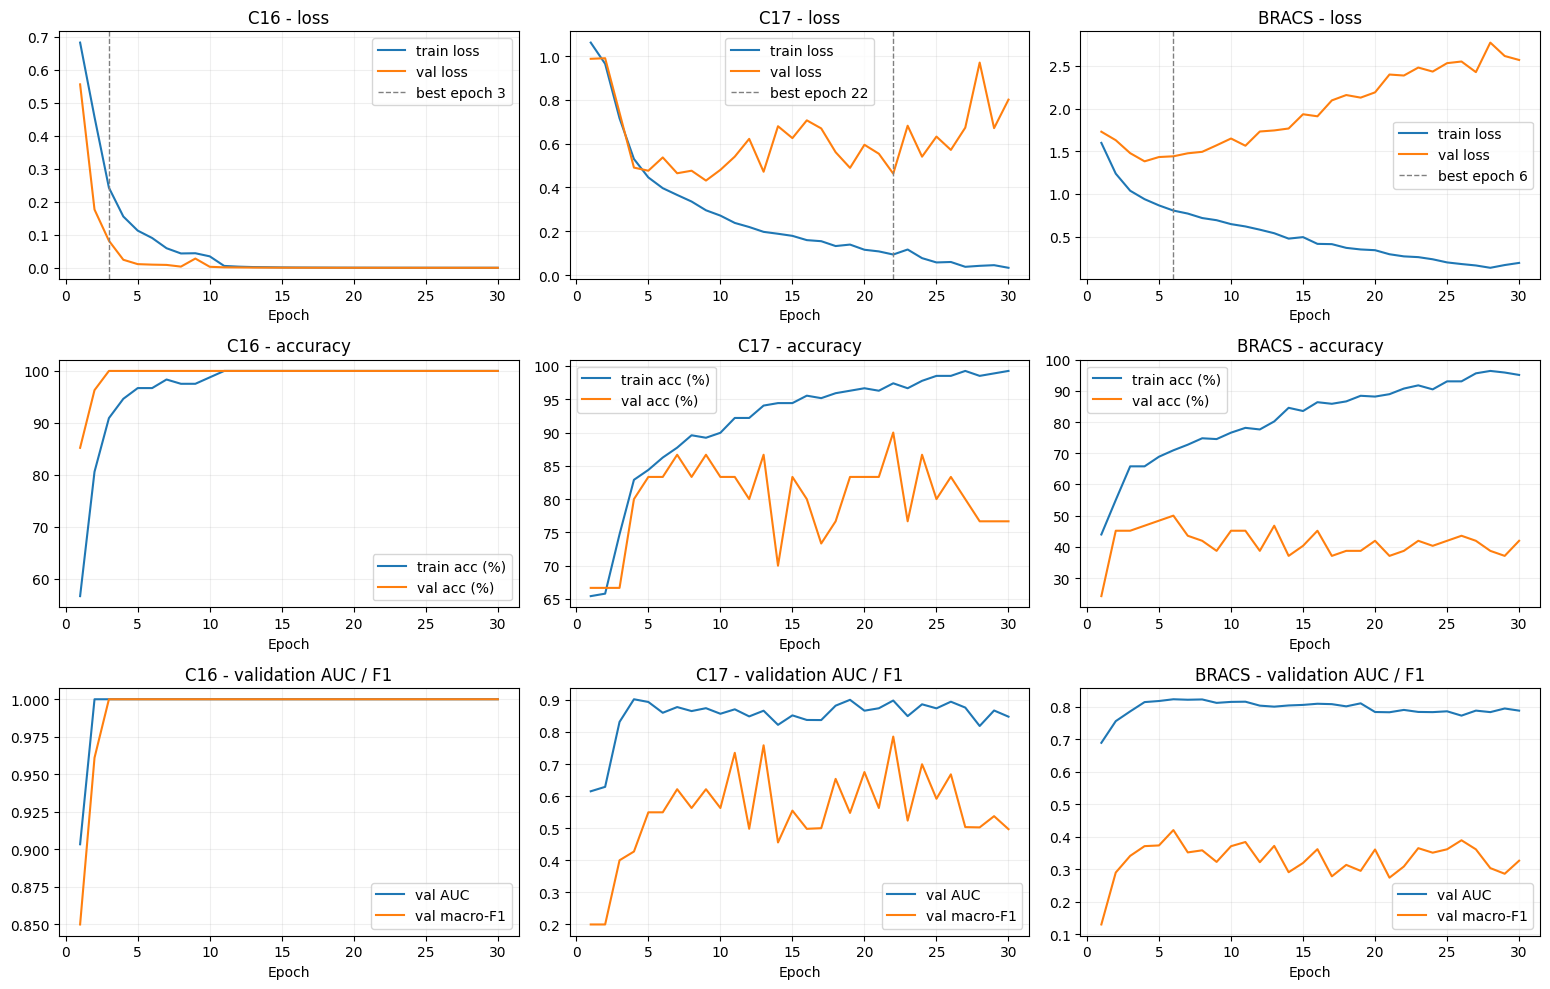

In [ ]:
fig, axes = plt.subplots(3, len(keys), figsize=(5.2 * len(keys), 10), squeeze=False)
for j, key in enumerate(keys):
    h = RESULTS[(key, first_seed)]["history"]
    be = RESULTS[(key, first_seed)]["best_epoch"]
    ax = axes[0, j]; ax.plot(h.epoch, h.train_loss, label="train loss"); ax.plot(h.epoch, h.val_loss, label="val loss")
    ax.axvline(be, color="gray", ls="--", lw=1, label=f"best epoch {be}")
    ax.set_title(f"{key} - loss"); ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.2)
    ax = axes[1, j]; ax.plot(h.epoch, h.train_acc, label="train acc (%)"); ax.plot(h.epoch, h.val_acc, label="val acc (%)")
    ax.set_title(f"{key} - accuracy"); ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.2)
    ax = axes[2, j]; ax.plot(h.epoch, h.val_auc, label="val AUC"); ax.plot(h.epoch, h.val_f1, label="val macro-F1")
    ax.set_title(f"{key} - validation AUC / F1"); ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.2)
plt.tight_layout(); plt.savefig("results/baseline_curves.png", dpi=200); plt.show()


===== C16: per-class test report =====
              precision    recall  f1-score   support

           0       0.84      1.00      0.91        80
           1       1.00      0.69      0.82        49

    accuracy                           0.88       129
   macro avg       0.92      0.85      0.87       129
weighted avg       0.90      0.88      0.88       129


===== C17: per-class test report =====
              precision    recall  f1-score   support

           0       0.92      0.93      0.92       121
           1       0.33      0.19      0.24        16
           2       0.21      0.17      0.19        18
           3       0.71      0.87      0.78        45

    accuracy                           0.79       200
   macro avg       0.54      0.54      0.53       200
weighted avg       0.76      0.79      0.77       200


===== BRACS: per-class test report =====
              precision    recall  f1-score   support

           0       0.33      0.17      0.22         6
       

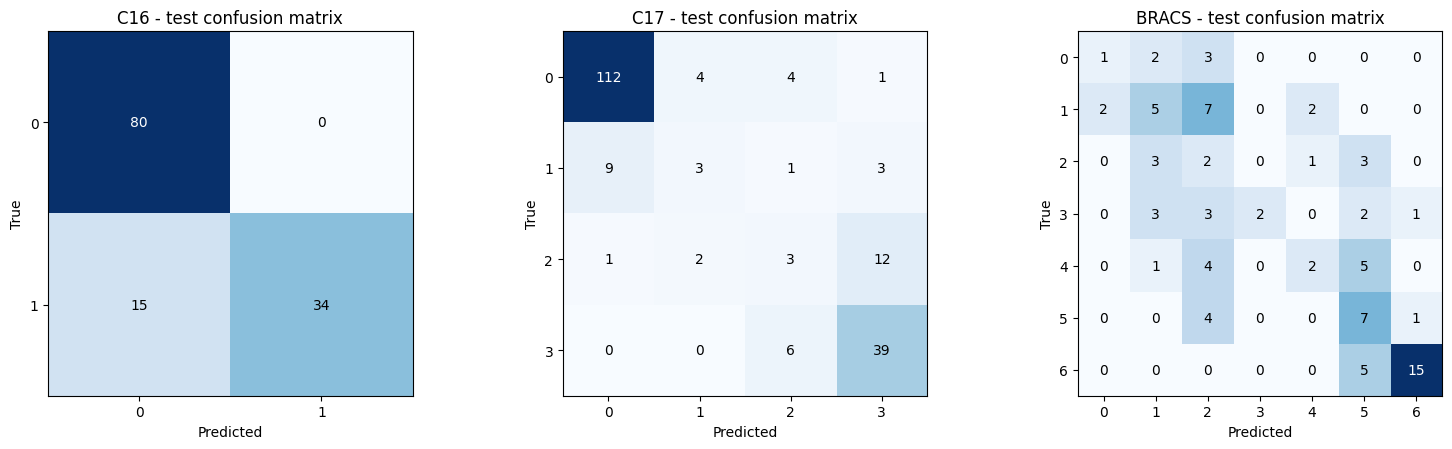

In [ ]:
fig, axes = plt.subplots(1, len(keys), figsize=(5.2 * len(keys), 4.6), squeeze=False)
for j, key in enumerate(keys):
    r = RESULTS[(key, first_seed)]
    n_class = int(r["conf"].n_class)
    y_true = r["test_labels"].numpy()
    y_pred = r["test_probs"].argmax(dim=1).numpy()
    cm = confusion_matrix(y_true, y_pred, labels=list(range(n_class)))
    ax = axes[0, j]; ax.imshow(cm, cmap="Blues")
    ax.set_title(f"{key} - test confusion matrix"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_xticks(range(n_class)); ax.set_yticks(range(n_class))
    for a in range(n_class):
        for b in range(n_class):
            ax.text(b, a, cm[a, b], ha="center", va="center", color="white" if cm[a, b] > cm.max() / 2 else "black")
    rep = classification_report(y_true, y_pred, labels=list(range(n_class)), zero_division=0)
    with open(f"results/{key}_per_class_report.txt", "w") as f:
        f.write(rep)
    print(f"\n===== {key}: per-class test report =====\n{rep}")
plt.tight_layout(); plt.savefig("results/baseline_confusion_matrices.png", dpi=200); plt.show()

In [ ]:
rows = []
for key in keys:
    r = RESULTS[(key, first_seed)]
    rows.append({"Dataset": key, "#Classes": int(r["conf"].n_class),
                 "Train (slides)": r["n_train"], "Val (slides)": r["n_val"], "Test (slides)": r["n_test"],
                 "Train class counts": r["counts"]["train"], "Val class counts": r["counts"]["val"],
                 "Test class counts": r["counts"]["test"]})
split_df = pd.DataFrame(rows)
split_df.to_csv("results/splits_and_class_counts.csv", index=False)
pd.set_option("display.max_colwidth", None)
display(split_df)

rows = []
for key in keys:
    r = RESULTS[(key, first_seed)]; h = r["history"]
    b = h[h.epoch == r["best_epoch"]].iloc[0]
    rows.append({"Dataset": key, "best epoch": r["best_epoch"],
                 "train loss (last)": h.train_loss.iloc[-1], "val loss (last)": h.val_loss.iloc[-1],
                 "train acc (last)": h.train_acc.iloc[-1], "val acc (last)": h.val_acc.iloc[-1],
                 "val loss (best epoch)": b.val_loss, "val AUC (best epoch)": b.val_auc})
gap_df = pd.DataFrame(rows)
gap_df.to_csv("results/overfitting_check.csv", index=False)
display(gap_df.round(4))

,Dataset,#Classes,Train (slides),Val (slides),Test (slides),Train class counts,Val class counts,Test class counts
0,C16,2,242,27,129,"{0: 142, 1: 100}","{0: 16, 1: 11}","{0: 80, 1: 49}"
1,C17,4,269,30,200,"{0: 177, 1: 18, 2: 37, 3: 37}","{0: 20, 1: 2, 2: 4, 3: 4}","{0: 121, 1: 16, 2: 18, 3: 45}"
2,BRACS,7,389,62,86,"{0: 24, 1: 119, 2: 54, 3: 24, 4: 28, 5: 40, 6: 100}","{0: 10, 1: 10, 2: 7, 3: 6, 4: 8, 5: 9, 6: 12}","{0: 6, 1: 16, 2: 9, 3: 11, 4: 12, 5: 12, 6: 20}"


,Dataset,best epoch,train loss (last),val loss (last),train acc (last),val acc (last),val loss (best epoch),val AUC (best epoch)
0,C16,3,0.0001,0.0000,100.0000,100.0000,0.0820,1.0000
1,C17,22,0.0332,0.8010,99.2565,76.6667,0.4630,0.8979
2,BRACS,6,0.1925,2.5681,95.1157,41.9355,1.4405,0.8232


In [ ]:
# 1) parameters per component
pc = count_params(RESULTS[(keys[0], first_seed)]["model"])
print("Parameters per component:")
for k, v in pc.items():
    print(f"  {k:32s} {v:>9,d}")
print(f"  {'TOTAL':32s} {sum(pc.values()):>9,d}")

# 2) attention statistics on the test slides
att_rows = []
for key in keys:
    d = RESULTS[(key, first_seed)]["att_df"]
    att_rows.append({"Dataset": key, "mean #patches/slide": d.n_patches.mean(),
                     "mean normalised attention entropy (1=uniform)": d.norm_entropy.mean(),
                     "mean attention mass on top-1% patches": d.top1pct_mass.mean()})
att_summary = pd.DataFrame(att_rows)
att_summary.to_csv("results/attention_summary.csv", index=False)
display(att_summary.round(4))

# 3) aggregator ablation: uniform (mean) pooling instead of learned attention
ABL = {}
abl_df = pd.DataFrame()
if RUN_ABLATION:
    for key in DATASETS_TO_RUN:
        ABL[key] = run_experiment(key, seed=first_seed, pooling="mean", epochs=NUM_EPOCHS, verbose=False)
    abl_rows = []
    for key in DATASETS_TO_RUN:
        a = RESULTS[(key, first_seed)]["test"]; m = ABL[key]["test"]
        abl_rows.append({"Dataset": key,
                         "ABMIL AUC": a["auc"], "MeanPool AUC": m["auc"], "dAUC": a["auc"] - m["auc"],
                         "ABMIL F1": a["f1"], "MeanPool F1": m["f1"], "dF1": a["f1"] - m["f1"],
                         "ABMIL Acc (%)": a["acc"], "MeanPool Acc (%)": m["acc"]})
    abl_df = pd.DataFrame(abl_rows)
    abl_df.to_csv("results/aggregator_ablation.csv", index=False)
    display(abl_df.round(4))

Parameters per component:
  encoder (DimReduction)              98,560
  aggregator (gated attention)        65,921
  classifier (1 FC)                      514
  TOTAL                              164,995


,Dataset,mean #patches/slide,mean normalised attention entropy (1=uniform),mean attention mass on top-1% patches
0,C16,12513.3643,0.8378,0.2627
1,C17,10575.0100,0.7195,0.3845
2,BRACS,9042.1279,0.7361,0.4554



########## C16 | seed 42 | pooling=mean ##########
Split sizes -> train 242 | val 27 | test 129 | D_feat 384 | n_class 2
Class counts: {'train': {0: 142, 1: 100}, 'val': {0: 16, 1: 11}, 'test': {0: 80, 1: 49}}
Trainable parameters: 164995 | epochs: 30
[C16] best val epoch = 25 | TEST: acc=67.44 auc=0.6584 f1=0.5883 loss=0.6443

########## C17 | seed 42 | pooling=mean ##########
Split sizes -> train 269 | val 30 | test 200 | D_feat 384 | n_class 4
Class counts: {'train': {0: 177, 1: 18, 2: 37, 3: 37}, 'val': {0: 20, 1: 2, 2: 4, 3: 4}, 'test': {0: 121, 1: 16, 2: 18, 3: 45}}
Trainable parameters: 165509 | epochs: 30
[C17] best val epoch = 1 | TEST: acc=60.50 auc=0.6443 f1=0.1885 loss=1.0310

########## BRACS | seed 42 | pooling=mean ##########
Split sizes -> train 389 | val 62 | test 86 | D_feat 384 | n_class 7
Class counts: {'train': {0: 24, 1: 119, 2: 54, 3: 24, 4: 28, 5: 40, 6: 100}, 'val': {0: 10, 1: 10, 2: 7, 3: 6, 4: 8, 5: 9, 6: 12}, 'test': {0: 6, 1: 16, 2: 9, 3: 11, 4: 12, 5: 12,

,Dataset,ABMIL AUC,MeanPool AUC,dAUC,ABMIL F1,MeanPool F1,dF1,ABMIL Acc (%),MeanPool Acc (%)
0,C16,0.9342,0.6584,0.2758,0.8668,0.5883,0.2785,88.3721,67.4419
1,C17,0.8391,0.6443,0.1948,0.5323,0.1885,0.3439,78.5000,60.5000
2,BRACS,0.8042,0.6616,0.1427,0.3494,0.2103,0.1391,39.5349,33.7209


In [ ]:
def table_md(df):
    try:
        return df.to_markdown(index=False)
    except Exception:
        return df.to_string(index=False)

r0 = RESULTS[(keys[0], first_seed)]; c = r0["conf"]; pc = count_params(r0["model"])
n_ep = len(r0["history"])
L = []
L.append("# ABMIL Baseline Evaluation Summary\n")

L.append("## 1. Key observations: model structure and training procedure\n")
L.append(f"- **Input.** Each slide is a bag of pre-extracted patch features from a frozen self-supervised backbone ({c.D_feat}-d per patch, variable number of patches per slide). Only the 3 modules below are trained.")
L.append(f"- **Encoder (DimReduction).** Linear({c.D_feat}->{c.D_inner}) + ReLU on every patch; {pc['encoder (DimReduction)']:,} parameters.")
L.append(f"- **Aggregator (gated attention).** a_i = w^T[tanh(V h_i) * sigmoid(U h_i)] with attention dim {c.D_attn}, softmax over the patches of a slide, slide embedding z = sum_i alpha_i h_i; {pc['aggregator (gated attention)']:,} parameters.")
L.append(f"- **Classifier.** One linear layer {c.D_inner}->n_classes on z; {pc['classifier (1 FC)']:,} parameters. Total trainable parameters: {sum(pc.values()):,} (for 2 classes; the classifier grows with n_classes).")
L.append(f"- **Training.** Cross-entropy loss, AdamW (lr={c.lr}, weight decay={c.wd}), batch size {c.B} slide per step, {n_ep} epochs, no learning-rate schedule, dropout {c.droprate}. Seed(s): {SEEDS}.")
L.append("- **Model selection / evaluation.** The epoch with the highest validation (macro-AUROC + macro-F1) is kept; the test set is evaluated once with that checkpoint. Metrics: accuracy, macro-AUROC, macro-F1, cross-entropy loss.")
L.append("- **Splits.** CAMELYON16: official test slides held out, 10% of the rest for validation. CAMELYON17: centers >= 3 held out as test (center-shift), 10% of the remaining slides for validation. BRACS: split given in the CSV.\n")
L.append(table_md(split_df[["Dataset", "#Classes", "Train (slides)", "Val (slides)", "Test (slides)"]]) + "\n")

L.append("## 2. Baseline performance\n")
L.append(table_md(summary_df) + "\n")
L.append("Figures: `baseline_curves.png` (loss / accuracy / val AUC & F1 per epoch), `baseline_confusion_matrices.png`.\n")
for key in keys:
    r = RESULTS[(key, first_seed)]; h = r["history"]
    gap = h.val_loss.iloc[-1] - h.train_loss.iloc[-1]
    L.append(f"- **{key}**: best validation epoch {r['best_epoch']}/{len(h)}; final train loss {h.train_loss.iloc[-1]:.3f} vs val loss {h.val_loss.iloc[-1]:.3f} (gap {gap:+.3f}); "
             f"test acc {r['test']['acc']:.2f}%, AUC {r['test']['auc']:.4f}, F1 {r['test']['f1']:.4f}. "
             f"Class counts (train/val/test): {r['counts']['train']} / {r['counts']['val']} / {r['counts']['test']}.")
L.append("")

L.append("## 3. What each component contributes\n")
L.append("- **Encoder:** turns generic frozen features into a task-specific lower-dimensional space where patches that matter for the slide label become separable; it is applied identically to every patch.")
L.append("- **Aggregator:** learns a per-patch importance score and pools the bag into one slide vector, so a small number of informative patches can dominate while the rest are down-weighted; it is also the only source of the interpretable attention map.")
L.append("- **Classifier:** a linear decision layer on the slide embedding that maps it to class scores (softmax gives probabilities used for AUROC).\n")
L.append("Attention statistics on test slides (normalised entropy 1 = uniform, 0 = a single patch):\n")
L.append(table_md(att_summary.round(4)) + "\n")
if len(abl_df):
    L.append("Aggregator ablation (same encoder/classifier, uniform mean pooling instead of learned attention, same split and seed):\n")
    L.append(table_md(abl_df.round(4)) + "\n")
    for _, row in abl_df.iterrows():
        verdict = "learned attention helped" if row["dAUC"] > 0 else "learned attention did not help"
        L.append(f"- **{row['Dataset']}**: dAUC = {row['dAUC']:+.4f}, dF1 = {row['dF1']:+.4f} -> {verdict} in this run (single seed; interpret small differences with care).")
    L.append("")

L.append("## 4. Caveats\n")
L.append("- Test sets are small and some classes have few slides, so macro-F1/AUC are noisy; report mean +/- std over several seeds when possible.")
L.append("- Attention weights show where the model looks, not causal evidence of what drives the prediction.")
L.append("- The same features, splits and seed must be reused for the research extension so the comparison with this baseline is fair.")

report = "\n".join(L)
with open("results/baseline_report_draft.md", "w") as f:
    f.write(report)
print(report)

# ABMIL Baseline Evaluation Summary

## 1. Key observations: model structure and training procedure

- **Input.** Each slide is a bag of pre-extracted patch features from a frozen self-supervised backbone (384-d per patch, variable number of patches per slide). Only the 3 modules below are trained.
- **Encoder (DimReduction).** Linear(384->256) + ReLU on every patch; 98,560 parameters.
- **Aggregator (gated attention).** a_i = w^T[tanh(V h_i) * sigmoid(U h_i)] with attention dim 128, softmax over the patches of a slide, slide embedding z = sum_i alpha_i h_i; 65,921 parameters.
- **Classifier.** One linear layer 256->n_classes on z; 514 parameters. Total trainable parameters: 164,995 (for 2 classes; the classifier grows with n_classes).
- **Training.** Cross-entropy loss, AdamW (lr=0.0001, weight decay=1e-05), batch size 1 slide per step, 30 epochs, no learning-rate schedule, dropout 0.0. Seed(s): [42].
- **Model selection / evaluation.** The epoch with the highest validation (macro-AUR

In [ ]:
shutil.make_archive("/content/baseline_results", "zip", os.path.join(PROJECT_DIR, "results"))
try:
    from google.colab import files
    files.download("/content/baseline_results.zip")
except Exception as e:
    print("Results zip saved at /content/baseline_results.zip", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
pip freeze

absl-py==1.4.0
accelerate==1.15.0
access==1.1.10.post3
affine==3.0.1
aiofiles==25.1.0
aiohappyeyeballs==2.7.1
aiohttp==3.14.3
aiosignal==1.4.0
aiosqlite==0.22.1
alabaster==1.0.0
albucore==0.0.24
albumentations==2.0.8
ale-py==0.12.1
altair==5.5.0
annotated-doc==0.0.5
annotated-types==0.8.0
antlr4-python3-runtime==4.9.3
anyio==4.15.1
anywidget==0.9.21
apsw==3.53.4.0
argon2-cffi==25.1.0
argon2-cffi-bindings==26.1.0
array_record==0.8.3
arrow==1.4.0
arviz==0.22.0
astropy==7.2.2
astropy-iers-data==0.2026.9.28.0.59.37
astunparse==1.6.3
atpublic==5.1
attrs==26.1.0
audioop-lts==0.2.2
audioread==3.1.0
Authlib==1.8.0
autograd==1.9.1
babel==2.18.0
backcall==0.2.0
beartype==0.22.9
beautifulsoup4==4.13.5
betterproto==2.0.0b7
bigframes==2.49.0
bigquery-magics==0.14.0
bleach==6.4.0
blinker==1.9.0
blis==1.3.3
blobfile==3.3.0
blosc2==4.14.1
bokeh==3.8.2
Bottleneck==1.4.2
bqplot==0.12.47
branca==0.8.2
brotli==1.2.0
CacheControl==0.14.4
cachetools==6.2.6
catalogue==2.0.10
certifi==2026.7.22
cffi==2.1.1
ch